# Módulo 56: Modelos ARIMA

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio [m56-modelos-arima-solucion.ipynb](m56-modelos-arima-solucion.ipynb). No es una tarea entregada del programa.

Los modelos AR explican una serie con sus propios rezagos, pero exigen que sea estacionaria y no capturan bien los choques que se disipan en pocos períodos. Los modelos **ARIMA** resuelven las dos cosas: **diferencian** la serie hasta volverla estacionaria (la I de "integrado") y combinan términos autorregresivos (AR) con términos de **media móvil** de los errores (MA). En esta lección se sigue la metodología de Box–Jenkins con las temperaturas medias anuales de Nueva York:

1. Cargar e inspeccionar los datos
2. Repaso: estacionariedad y prueba ADF
3. Diferenciación y el orden d
4. Modelos MA(q) y su ACF
5. ARMA y ARIMA con el operador de rezago
6. Identificación de Box–Jenkins
7. Elegir el orden con una rejilla de AIC
8. Pronóstico con `get_forecast`
9. Diagnóstico de residuos
10. Errores frecuentes
11. Ejercicio

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning

## 1. Cargar e inspeccionar los datos

Antes de modelar conviene mirar el archivo tal como está en disco. `temperatura-ny.csv` empieza con una **marca de orden de bytes** (BOM, los bytes `EF BB BF` que algunos programas añaden al guardar en UTF-8) y cada línea termina en una coma, lo que crea una tercera columna vacía.

In [2]:
with open("temperatura-ny.csv", "rb") as archivo:
    crudo = archivo.read(60)
print(crudo)

print(pd.read_csv("temperatura-ny.csv").columns.tolist())

b'\xef\xbb\xbfYear,Average,\r\n1870,53.60,\r\n1871,51.13,\r\n1872,50.98,\r\n187'
['Year', 'Average', 'Unnamed: 2']


`encoding="utf-8-sig"` descarta el BOM de forma explícita y `usecols=[0, 1]` ignora la columna vacía. Se convierte el año en fechas con frecuencia anual (`"YS"`, inicio de año) para que `statsmodels` sepa fechar los pronósticos.

¿Años consecutivos? True
count    151.00
mean      54.00
std        1.70
min       49.34
25%       52.96
50%       54.02
75%       55.18
max       57.31
Name: temperatura, dtype: float64


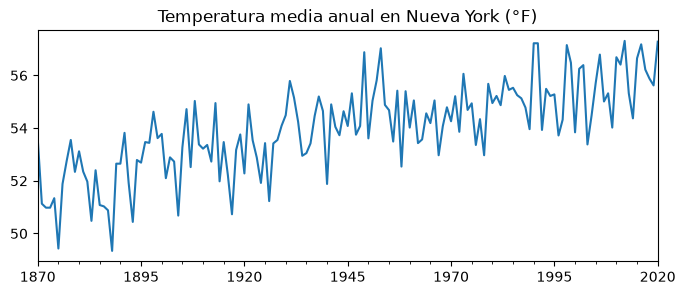

In [3]:
temp = pd.read_csv("temperatura-ny.csv", encoding="utf-8-sig", usecols=[0, 1])
temp.index = pd.date_range(start=f"{temp['Year'].iloc[0]}-01-01", periods=len(temp), freq="YS")
serie = temp["Average"].rename("temperatura")

print("¿Años consecutivos?", (temp["Year"].diff().dropna() == 1).all())
print(serie.describe().round(2))

fig, ax = plt.subplots(figsize=(8, 3))
serie.plot(ax=ax, title="Temperatura media anual en Nueva York (°F)")
plt.show()

## 2. Repaso: estacionariedad y prueba ADF

La prueba de Dickey–Fuller aumentada contrasta $H_0$: la serie tiene raíz unitaria (no es estacionaria), frente a $H_1$: es estacionaria. Un p-valor menor que 0.05 permite rechazar la raíz unitaria.

In [4]:
def adf(serie_, nombre):
    estadistico, p_valor, *_ = adfuller(serie_.dropna())
    print(f"{nombre:<24} ADF={estadistico:7.2f}  p={p_valor:.4f}")

adf(serie, "Temperatura")

Temperatura              ADF=  -0.72  p=0.8417


Con p = 0.84, no se puede rechazar la raíz unitaria: la serie tiene una tendencia de calentamiento y su nivel no es estable.

## 3. Diferenciación y el orden d

La **primera diferencia** $\nabla y_t = y_t - y_{t-1}$ convierte una tendencia en cambios año a año. Si todavía no es estacionaria, se diferencia otra vez: $\nabla^2 y_t = \nabla y_t - \nabla y_{t-1}$. El número de diferencias necesarias es el orden **d** del ARIMA. Casi nunca hace falta pasar de $d = 2$.

Primera diferencia       ADF=  -8.57  p=0.0000


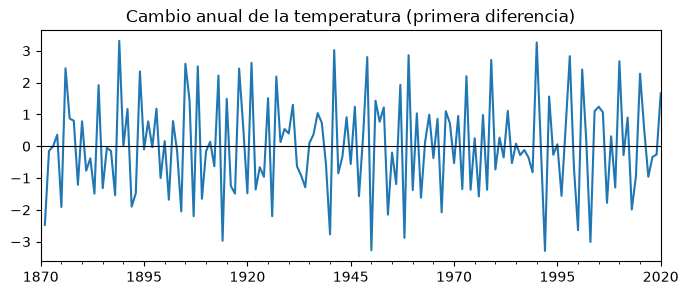

In [5]:
dif1 = serie.diff()
adf(dif1, "Primera diferencia")

fig, ax = plt.subplots(figsize=(8, 3))
dif1.plot(ax=ax, title="Cambio anual de la temperatura (primera diferencia)")
ax.axhline(0, color="k", lw=0.8)
plt.show()

Con una diferencia la serie ya es estacionaria (p prácticamente 0), así que $d = 1$.

## 4. Modelos MA(q) y su ACF

Un proceso de **media móvil de orden q** combina el error actual con los q anteriores:

$$y_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q}.$$

Un choque afecta exactamente q períodos y luego desaparece. Por eso la **ACF de un MA(q) se corta después del rezago q**. Para un MA(1), $\rho_1 = \theta_1/(1 + \theta_1^2)$ y $\rho_k = 0$ para $k \ge 2$; su PACF, en cambio, decae poco a poco.

ρ1 teórica: 0.441   muestral: 0.494


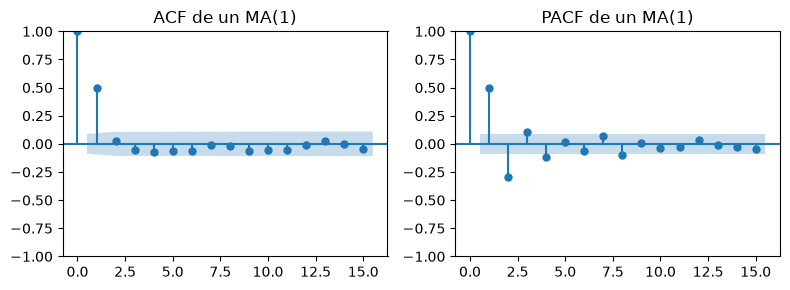

In [6]:
rng = np.random.default_rng(42)
theta = 0.6
ma1 = ArmaProcess(ar=[1], ma=[1, theta]).generate_sample(nsample=500, distrvs=rng.standard_normal)

print(f"ρ1 teórica: {theta / (1 + theta ** 2):.3f}   muestral: {acf(ma1, nlags=1)[1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
plot_acf(ma1, lags=15, ax=axes[0], title="ACF de un MA(1)")
plot_pacf(ma1, lags=15, ax=axes[1], method="ywm", title="PACF de un MA(1)")
plt.tight_layout()
plt.show()

## 5. ARMA y ARIMA con el operador de rezago

El **operador de rezago** $B$ desplaza la serie un período: $B y_t = y_{t-1}$, $B^k y_t = y_{t-k}$, y la diferencia se escribe $\nabla = 1 - B$. Con los polinomios

$$\phi(B) = 1 - \phi_1 B - \dots - \phi_p B^p, \qquad \theta(B) = 1 + \theta_1 B + \dots + \theta_q B^q,$$

los modelos se escriben de forma compacta:

| Modelo | Ecuación |
| --- | --- |
| AR(p) | $\phi(B)\, y_t = c + \varepsilon_t$ |
| MA(q) | $y_t = \mu + \theta(B)\, \varepsilon_t$ |
| ARMA(p, q) | $\phi(B)\, y_t = c + \theta(B)\, \varepsilon_t$ |
| ARIMA(p, d, q) | $\phi(B)\, (1 - B)^d\, y_t = c + \theta(B)\, \varepsilon_t$ |

Un ARIMA(p, d, q) es un ARMA(p, q) aplicado a la serie diferenciada d veces. En `statsmodels`, cuando $d \ge 1$ el modelo no incluye constante por defecto; para una deriva en la serie diferenciada se añade `trend="t"`.

## 6. Identificación de Box–Jenkins

La metodología de **Box–Jenkins** tiene cuatro pasos: identificar (elegir d, luego p y q), estimar, diagnosticar los residuos y pronosticar. Para p y q se comparan la ACF y la PACF de la serie ya diferenciada con estos patrones:

| Proceso | ACF | PACF |
| --- | --- | --- |
| AR(p) | Decae gradualmente | Se corta después de p |
| MA(q) | Se corta después de q | Decae gradualmente |
| ARMA(p, q) | Decae después de q | Decae después de p |

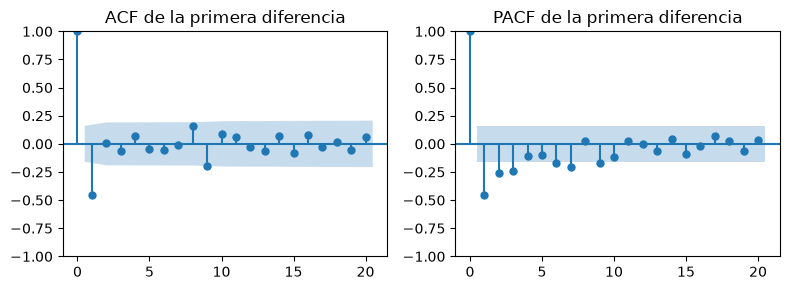

ACF, rezagos 1 a 3:  [-0.458  0.005 -0.059]


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
plot_acf(dif1.dropna(), lags=20, ax=axes[0], title="ACF de la primera diferencia")
plot_pacf(dif1.dropna(), lags=20, ax=axes[1], method="ywm", title="PACF de la primera diferencia")
plt.tight_layout()
plt.show()

print("ACF, rezagos 1 a 3: ", acf(dif1.dropna(), nlags=3)[1:].round(3))

La ACF de la diferencia tiene una barra negativa grande en el rezago 1 y después queda casi siempre dentro de la banda, mientras que la PACF decae en varios rezagos negativos: el patrón se parece al de un MA(1). Ese es el punto de partida; la rejilla de AIC confirma o corrige la propuesta.

## 7. Elegir el orden con una rejilla de AIC

Se reservan los últimos 15 años para la prueba y se ajustan todos los ARIMA(p, 1, q) con $p, q \in \{0, 1, 2\}$ sobre el entrenamiento. Se elige el de menor AIC.

El optimizador de máxima verosimilitud a veces no converge para algún orden y emite un `ConvergenceWarning`. No es un error del código, pero sí significa que el AIC de ese orden es poco fiable. Por eso el aviso se **captura solo en la llamada a `fit()`** con `warnings.catch_warnings(record=True)`: no ensucia la salida, pero queda registrado en la tabla para tenerlo en cuenta. Silenciar todos los avisos del notebook con `warnings.filterwarnings("ignore")` ocultaría problemas reales.

In [8]:
entrenamiento, prueba = serie.iloc[:-15], serie.iloc[-15:]

filas = []
for p in range(3):
    for q in range(3):
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always", ConvergenceWarning)
            ajuste = ARIMA(entrenamiento, order=(p, 1, q)).fit()
        convergio = not any(issubclass(a.category, ConvergenceWarning) for a in avisos)
        filas.append({"orden": (p, 1, q), "AIC": round(ajuste.aic, 2), "convergió": convergio})

rejilla = pd.DataFrame(filas).sort_values("AIC").reset_index(drop=True)
rejilla

,orden,AIC,convergió
0,"(0, 1, 1)",436.12,True
1,"(1, 1, 1)",437.72,True
2,"(0, 1, 2)",437.76,True
3,"(2, 1, 2)",439.23,True
4,"(2, 1, 1)",439.43,True
5,"(1, 1, 2)",439.56,True
6,"(2, 1, 0)",456.58,True
7,"(1, 1, 0)",466.48,True
8,"(0, 1, 0)",499.82,True


In [9]:
orden = rejilla.loc[0, "orden"]
modelo = ARIMA(entrenamiento, order=orden).fit()
print("Orden elegido:", orden)
print(modelo.summary().tables[1])

Orden elegido: (0, 1, 1)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.8547      0.049    -17.294      0.000      -0.952      -0.758
sigma2         1.4238      0.209      6.827      0.000       1.015       1.833


## 8. Pronóstico con `get_forecast`

`get_forecast(steps)` pronostica los siguientes `steps` períodos. Su atributo `predicted_mean` es el pronóstico puntual, y `conf_int(alpha=0.1)` da el intervalo al 90 %, que se ensancha con el horizonte.

MSE=1.673  MAPE=1.96 %  cobertura del intervalo al 90 %: 93%


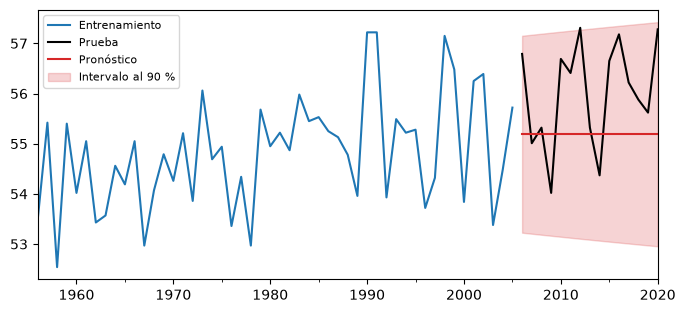

In [10]:
pronostico = modelo.get_forecast(steps=len(prueba))
media = pronostico.predicted_mean
intervalo = pronostico.conf_int(alpha=0.10)

mse = np.mean((prueba - media) ** 2)
mape = 100 * np.mean(np.abs((prueba - media) / prueba))
dentro = ((prueba >= intervalo.iloc[:, 0]) & (prueba <= intervalo.iloc[:, 1])).mean()
print(f"MSE={mse:.3f}  MAPE={mape:.2f} %  cobertura del intervalo al 90 %: {dentro:.0%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
entrenamiento.iloc[-50:].plot(ax=ax, label="Entrenamiento")
prueba.plot(ax=ax, label="Prueba", color="k")
media.plot(ax=ax, label="Pronóstico", color="C3")
ax.fill_between(intervalo.index, intervalo.iloc[:, 0], intervalo.iloc[:, 1], color="C3", alpha=0.2,
                label="Intervalo al 90 %")
ax.legend(loc="upper left", fontsize=8)
plt.show()

Un ARIMA con $d = 1$ y sin deriva pronostica un nivel casi plano: no extrapola la tendencia de calentamiento. Aun así, 14 de los 15 años de prueba (93 %) quedan dentro del intervalo al 90 %, y el MAPE es menor al 2 %.

## 9. Diagnóstico de residuos

Si el modelo captura toda la estructura, sus residuos deben ser **ruido blanco**. La prueba de **Ljung–Box** lo contrasta con las primeras $h$ autocorrelaciones de los residuos:

$$Q = n(n+2) \sum_{k=1}^{h} \frac{\hat\rho_k^2}{n-k} \sim \chi^2_{h-p-q} \text{ bajo } H_0: \text{no hay autocorrelación}.$$

Los grados de libertad se reducen en $p + q$ porque esos parámetros se estimaron con los mismos datos (`model_df=p+q`). Con $d = 1$, el primer residuo no tiene un valor anterior con el cual compararse y coincide con la primera observación, así que se descarta.

In [11]:
residuos = modelo.resid
print("Primer residuo:", round(residuos.iloc[0], 2), " primera observación:", entrenamiento.iloc[0])

p_, _, q_ = orden
lb = acorr_ljungbox(residuos.iloc[1:], lags=[5, 10], model_df=p_ + q_, return_df=True)
lb

Primer residuo: 53.6  primera observación: 53.6


,lb_stat,lb_pvalue
5,5.068387,0.280352
10,12.604600,0.181329


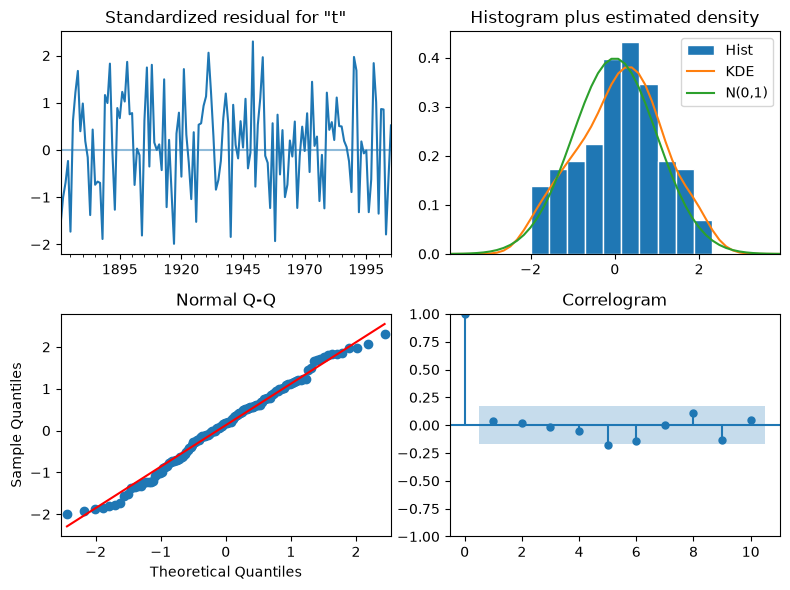

In [12]:
fig = modelo.plot_diagnostics(figsize=(8, 6))
plt.tight_layout()
plt.show()

Los p-valores de Ljung–Box son mayores que 0.05: no hay evidencia de autocorrelación en los residuos. `plot_diagnostics` muestra cuatro vistas: los residuos estandarizados en el tiempo, su histograma con la densidad normal, la gráfica Q-Q y su correlograma. Esta función ya omite el período de inicialización, por eso el primer residuo no aparece. Aquí los residuos se ven razonablemente normales y su correlograma queda dentro de la banda.

## 10. Errores frecuentes

**Leer un CSV sin inspeccionarlo.** Un BOM puede quedar pegado al nombre de la primera columna en algunos lectores, y una coma final crea columnas vacías. Basta con mirar los primeros bytes y la lista de columnas, como en la sección 1.

**Incluir el primer residuo en la prueba de Ljung–Box.** Con $d \ge 1$ ese residuo es enorme e infla la varianza que divide a cada autocorrelación. Las autocorrelaciones salen artificialmente pequeñas y los p-valores, cercanos a 1: una falsa tranquilidad.

In [13]:
print("Con el primer residuo:")
print(acorr_ljungbox(residuos, lags=[5, 10], model_df=p_ + q_, return_df=True).round(4))

Con el primer residuo:
    lb_stat  lb_pvalue
5    0.8212     0.9356
10   1.1709     0.9989


**Sobrediferenciar.** Diferenciar una serie que ya es estacionaria introduce una autocorrelación negativa artificial y aumenta la varianza. Una autocorrelación de orden 1 cercana a −0.5 tras diferenciar es una señal de alarma:

In [14]:
ruido_blanco = pd.Series(np.random.default_rng(42).normal(size=500))
print(f"Varianza: original {ruido_blanco.var():.2f}, diferenciada {ruido_blanco.diff().var():.2f}")
print(f"ρ1 de la serie diferenciada: {acf(ruido_blanco.diff().dropna(), nlags=1)[1]:.3f}")

Varianza: original 0.92, diferenciada 1.66
ρ1 de la serie diferenciada: -0.447


**Silenciar todos los avisos.** `warnings.filterwarnings("ignore")` al inicio oculta avisos de convergencia, de frecuencia de fechas o de funciones obsoletas. Es mejor capturar solo el aviso esperado en la línea concreta, como en la sección 7.

**Elegir el orden solo por AIC.** Un AIC bajo no garantiza residuos limpios; el diagnóstico de la sección 9 es parte del método, no un adorno.

## 11. Ejercicio

Simula una serie integrada cuyos cambios siguen un ARMA(1, 1):

```python
rng = np.random.default_rng(42)
cambios = ArmaProcess(ar=[1, -0.5], ma=[1, 0.4]).generate_sample(nsample=240, distrvs=rng.standard_normal)
nivel = pd.Series(50 + np.cumsum(cambios),
                  index=pd.date_range("2005-01-01", periods=240, freq="MS"))
```

1. Aplica la prueba ADF al nivel y a su primera diferencia. ¿Qué d corresponde?
2. Separa los últimos 24 meses como prueba.
3. Ajusta ARIMA(p, d, q) con $p, q \in \{0, 1, 2\}$, capturando solo los `ConvergenceWarning`, y elige por AIC.
4. Pronostica los 24 meses con intervalos al 90 % y calcula el MSE.
5. Aplica Ljung–Box a los residuos del modelo elegido, sin el primero.

### Solución

In [15]:
rng = np.random.default_rng(42)
cambios = ArmaProcess(ar=[1, -0.5], ma=[1, 0.4]).generate_sample(nsample=240, distrvs=rng.standard_normal)
nivel = pd.Series(50 + np.cumsum(cambios), index=pd.date_range("2005-01-01", periods=240, freq="MS"))

# 1. d por ADF
adf(nivel, "Nivel")
adf(nivel.diff(), "Primera diferencia")

# 2. División cronológica
n_tr, n_te = nivel.iloc[:-24], nivel.iloc[-24:]

# 3. Rejilla por AIC
resultados = []
for p in range(3):
    for q in range(3):
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always", ConvergenceWarning)
            r = ARIMA(n_tr, order=(p, 1, q)).fit()
        resultados.append(((p, 1, q), r.aic, not any(issubclass(a.category, ConvergenceWarning) for a in avisos)))
tabla = pd.DataFrame(resultados, columns=["orden", "AIC", "convergió"]).sort_values("AIC")
print(tabla.round(2).to_string(index=False))

Nivel                    ADF=  -0.95  p=0.7713
Primera diferencia       ADF=  -9.52  p=0.0000
    orden    AIC  convergió
(2, 1, 0) 554.98       True
(2, 1, 1) 556.81       True
(1, 1, 2) 558.05       True
(2, 1, 2) 558.80       True
(0, 1, 2) 559.67       True
(1, 1, 1) 562.41       True
(1, 1, 0) 593.74       True
(0, 1, 1) 596.21       True
(0, 1, 0) 734.29       True


In [16]:
# 4. Pronóstico con el mejor orden
mejor = tabla.iloc[0]["orden"]
ajuste = ARIMA(n_tr, order=mejor).fit()
fc = ajuste.get_forecast(steps=24)
print("Orden:", mejor, f" MSE={np.mean((n_te - fc.predicted_mean) ** 2):.3f}")
print(fc.conf_int(alpha=0.10).iloc[[0, -1]].round(2))

# 5. Ljung–Box sin el primer residuo
pp, _, qq = mejor
print(acorr_ljungbox(ajuste.resid.iloc[1:], lags=[10], model_df=pp + qq, return_df=True).round(4))

Orden: (2, 1, 0)  MSE=25.682
            lower y  upper y
2023-01-01    22.51    25.35
2024-12-01     8.48    40.76
    lb_stat  lb_pvalue
10   6.6312     0.5769


La ADF indica $d = 1$. La rejilla elige ARIMA(2, 1, 0) aunque la serie se simuló como ARIMA(1, 1, 1), que queda unos 7 puntos de AIC por detrás. No es una contradicción: escribiendo el ARMA(1, 1) como un AR infinito, $(1 - 0.5B)/(1 + 0.4B) = 1 - 0.9B + 0.36B^2 - 0.144B^3 + \dots$, sus dos primeros coeficientes dominan, y un AR(2) los aproxima bien. El intervalo se ensancha mucho del primer al último mes, como corresponde a una serie integrada, y Ljung–Box no detecta autocorrelación en los residuos.

## Resumen

- La diferenciación $\nabla y_t = (1 - B) y_t$ vuelve estacionaria una serie con raíz unitaria; el número de diferencias es el orden d.
- La ACF de un MA(q) se corta en q, y la PACF de un AR(p), en p; un ARIMA(p, d, q) es un ARMA(p, q) sobre la serie diferenciada: $\phi(B)(1 - B)^d y_t = c + \theta(B)\varepsilon_t$.
- Box–Jenkins: identificar con ADF, ACF y PACF; estimar; diagnosticar; pronosticar. La rejilla por AIC afina la propuesta.
- `get_forecast(steps)` da `predicted_mean` y `conf_int(alpha)`, con intervalos que crecen con el horizonte.
- Ljung–Box sobre los residuos (sin el primero cuando $d \ge 1$) comprueba que sean ruido blanco.
- Los avisos de convergencia se capturan en la llamada concreta, nunca se silencian de forma global.

En el **Módulo 57** se cierra el programa con el storytelling: cómo convertir un análisis en una historia clara para quien toma decisiones.